In [280]:
import pandas as pd
import numpy as np
import copy

In [281]:
#Abrir o arquivo
arquivo =  './Servidores_IFSP_arrumado.csv'
df = pd.read_csv(arquivo,sep=';')

df

,SERVIDOR,EXERCICIO SIAPE,LOTACAO SIAPE,CARGO EMPREGO,DATA POSSE NO CARGO,FUNCAO DISPLAY,JORNADA TRABALHO,NOME DO SETOR DE EXERCÍCIO POR EXTENSO,SITUACAO,TITULACAO
0,Abner Branchini Goncalves,Reitoria,Reitoria,TECNICO EM CONTABILIDADE (PCIFE) - 701224,11/08/2011,NaN,40 HORAS SEMANAIS,COORDENADORIA DE CONTRATOS,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR
1,Abner Nunes Emerich de Paula,NaN,NaN,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/04/2025,NaN,DEDICACAO EXCLUSIVA,COLAB PCCTAE E MAGIS - 41,NaN,NaN
2,Abraao Pustrelo Damiao,Barretos,Barretos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,22/09/2014,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DA AREA DE ALIMENTOS,ATIVO PERMANENTE - 01,DOUTORADO
3,Abrao Jorge,Reitoria,NaN,ASSISTENTE EM ADMINISTRACAO (PCIFE) - 701200,01/01/2010,NaN,40 HORAS SEMANAIS,REITORIA,APOSENTADO - 02,NaN
4,Acacia dos Campos da Terra,Itapetininga,Itapetininga,PROF ENS BAS TEC TECNOLOGICO-SUBSTITUTO (CMEBT...,26/08/2024,NaN,40 HORAS SEMANAIS,COORD CURSO TEC INFORMATICA,CONT.PROF.SUBSTITUTO - 52,MESTRADO
...,...,...,...,...,...,...,...,...,...,...
5590,Zady Castaneda Salazar,Campinas,Campinas,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,22/01/2014,NaN,DEDICACAO EXCLUSIVA,FUC CURSO SUP TEC ADS,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18)
5591,Zenilton Jose da Rocha,Capivari,Capivari,TECNOLOGO-FORMACAO (PCIFE) - 701081,23/04/2019,FG2,40 HORAS SEMANAIS,"COORD MANUT, ALMOX E PATRIMONIO",ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR
5592,Zeno Queiroz Costa,Pirituba,Pirituba,PROF ENS BAS TEC TECNOLOGICO-SUBSTITUTO (CMEBT...,10/03/2025,NaN,40 HORAS SEMANAIS,COORD CUR DE LIC EM LETRAS (PORT/INGLES),CONT.PROF.SUBSTITUTO - 52,MESTRADO
5593,Zilda Stonoga Kawamoto,Reitoria,NaN,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/01/2010,NaN,DEDICACAO EXCLUSIVA,REITORIA,APOSENTADO - 02,ESPECIALIZACAO NIVEL SUPERIOR


In [282]:
#Pegando as Titulações
titulos = df['TITULACAO'].unique()
titulos

<StringArray>
[           'ESPECIALIZACAO NIVEL SUPERIOR',
                                        nan,
                                'DOUTORADO',
                                 'MESTRADO',
      'GRADUACAO (NIVEL SUPERIOR COMPLETO)',
     'MESTRE+RSC-III (LEI 12772/12 ART 18)',
 'POS-GRADUAÇÃO+RSC-II LEI 12772/12 ART 18',
           'TECNICO (NIVEL MEDIO COMPLETO)',
   'GRADUAÇÃO+RSC-I (LEI 12772/12 ART. 18)',
                            'POS-GRADUACAO',
                              'NIVEL MÉDIO',
           'APERFEICOAMENTO NIVEL SUPERIOR']
Length: 12, dtype: str

In [283]:
#Retirando os Aposentados:
df = df[df['SITUACAO'] != 'APOSENTADO - 02']

#Retirando os sem titulação:
df = df.dropna(subset=['TITULACAO'])

#Retirando as cidades não desejadas:
cidades_escolhidas = [
    'São Paulo',
    'Sertãozinho',
    'São José dos Campos',
    'Jacarei',
    'Cubatão',
    'Hortolândia',
    'Presidente Epitácio',
    'Barretos',
    'Salto',
    'Suzano'

]

df = df[df[' EXERCICIO SIAPE'].isin(cidades_escolhidas)]

df

,SERVIDOR,EXERCICIO SIAPE,LOTACAO SIAPE,CARGO EMPREGO,DATA POSSE NO CARGO,FUNCAO DISPLAY,JORNADA TRABALHO,NOME DO SETOR DE EXERCÍCIO POR EXTENSO,SITUACAO,TITULACAO
2,Abraao Pustrelo Damiao,Barretos,Barretos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,22/09/2014,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DA AREA DE ALIMENTOS,ATIVO PERMANENTE - 01,DOUTORADO
7,Adaiana Francisca Gomes da Silva,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,09/09/2014,NaN,DEDICACAO EXCLUSIVA,COORD DO CURSO DE ENGENHARIA MECANICA,ATIVO PERMANENTE - 01,DOUTORADO
19,Adelino Zamprogno,São Paulo,São Paulo,ASSISTENTE EM ADMINISTRACAO (PCIFE) - 701200,09/08/2021,FG1,40 HORAS SEMANAIS,COORDENADORIA DE LICITACOES,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR
25,Ademir Sousa Henrique,São Paulo,São Paulo,TECNICO EM ASSUNTOS EDUCACIONAIS (PCIFE) - 701079,17/08/2020,NaN,40 HORAS SEMANAIS,COORDENADORIA DE BIBLIOTECA,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR
32,Adilson de Melo Poggiato,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,40 HORAS SEMANAIS,COORD DE CURSO TECNICO EM AUT INDUSTRIAL,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR
...,...,...,...,...,...,...,...,...,...,...
5566,Wilson de Andrade Matos,São Paulo,São Paulo,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,REPRES. DA SUBAREA DE FISICA,ATIVO PERMANENTE - 01,MESTRADO
5570,Wilson Mitsuo Uaquida,São Paulo,São Paulo,TECNICO DE LABORATORIO AREA (PCIFE) - 701244,27/03/2013,NaN,40 HORAS SEMANAIS,SUB AREA DE ELETRICA 4,ATIVO PERMANENTE - 01,GRADUACAO (NIVEL SUPERIOR COMPLETO)
5576,Wilson Sergio de Araujo Rocha,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,COORD CURSO DE LICENCIATURA EM QUIMICA,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18)
5578,Wilson Yoshio Tanaka,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,06/06/2016,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DE CURSO TEC EM ADM E COM,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18)


In [284]:
#Criando pesos:

pesos = {'DOUTORADO': 10,
         'MESTRE+RSC-III (LEI 12772/12 ART 18)': 9,
         'MESTRADO': 8,
         'POS-GRADUAÇÃO+RSC-II LEI 12772/12 ART 18': 7,
         'ESPECIALIZACAO NIVEL SUPERIOR': 6,
         'POS-GRADUACAO': 5,
         'GRADUAÇÃO+RSC-I (LEI 12772/12 ART. 18)': 4,
         'GRADUACAO (NIVEL SUPERIOR COMPLETO)': 3,
         'TECNICO (NIVEL MEDIO COMPLETO)': 2,
         'NIVEL MÉDIO': 1
         }

#Criando uma tabela com os pesos

tabela_pesos = pd.DataFrame(list(pesos.items()), columns=['TITULACAO', 'PESO'])



df['TITULACAO'].unique()
tabela_pesos


,TITULACAO,PESO
0,DOUTORADO,10
1,MESTRE+RSC-III (LEI 12772/12 ART 18),9
2,MESTRADO,8
3,POS-GRADUAÇÃO+RSC-II LEI 12772/12 ART 18,7
4,ESPECIALIZACAO NIVEL SUPERIOR,6
5,POS-GRADUACAO,5
6,GRADUAÇÃO+RSC-I (LEI 12772/12 ART. 18),4
7,GRADUACAO (NIVEL SUPERIOR COMPLETO),3
8,TECNICO (NIVEL MEDIO COMPLETO),2
9,NIVEL MÉDIO,1


In [285]:
#Adicionando pesos a tabela original
dados = pd.merge(df,tabela_pesos,on='TITULACAO')
dados['ID'] = range(0, len(df))

#Adicionando a disciplina de cada professor (sorteada com as porcentagens abaixo)
disciplinas = ['portugues', 'matematica', 'fisica', 'quimica', 'biologia', 'historia',
               'geografia', 'artes', 'sociologia', 'filosofia', 'educacao fisica', 'ingles']
porcentagens = [0.12, 0.12, 0.09, 0.09, 0.09, 0.08,
                0.08, 0.06, 0.06, 0.06, 0.08, 0.07]

#Usando seed para o sorteio dar sempre o mesmo resultado
np.random.seed(42)  
dados['DISCIPLINA'] = np.random.choice(disciplinas, size=len(dados), p=porcentagens)
dados

,SERVIDOR,EXERCICIO SIAPE,LOTACAO SIAPE,CARGO EMPREGO,DATA POSSE NO CARGO,FUNCAO DISPLAY,JORNADA TRABALHO,NOME DO SETOR DE EXERCÍCIO POR EXTENSO,SITUACAO,TITULACAO,PESO,ID,DISCIPLINA
0,Abraao Pustrelo Damiao,Barretos,Barretos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,22/09/2014,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DA AREA DE ALIMENTOS,ATIVO PERMANENTE - 01,DOUTORADO,10,0,quimica
1,Adaiana Francisca Gomes da Silva,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,09/09/2014,NaN,DEDICACAO EXCLUSIVA,COORD DO CURSO DE ENGENHARIA MECANICA,ATIVO PERMANENTE - 01,DOUTORADO,10,1,ingles
2,Adelino Zamprogno,São Paulo,São Paulo,ASSISTENTE EM ADMINISTRACAO (PCIFE) - 701200,09/08/2021,FG1,40 HORAS SEMANAIS,COORDENADORIA DE LICITACOES,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,2,sociologia
3,Ademir Sousa Henrique,São Paulo,São Paulo,TECNICO EM ASSUNTOS EDUCACIONAIS (PCIFE) - 701079,17/08/2020,NaN,40 HORAS SEMANAIS,COORDENADORIA DE BIBLIOTECA,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,3,geografia
4,Adilson de Melo Poggiato,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,40 HORAS SEMANAIS,COORD DE CURSO TECNICO EM AUT INDUSTRIAL,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,4,matematica
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690,Wilson de Andrade Matos,São Paulo,São Paulo,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,REPRES. DA SUBAREA DE FISICA,ATIVO PERMANENTE - 01,MESTRADO,8,1690,matematica
1691,Wilson Mitsuo Uaquida,São Paulo,São Paulo,TECNICO DE LABORATORIO AREA (PCIFE) - 701244,27/03/2013,NaN,40 HORAS SEMANAIS,SUB AREA DE ELETRICA 4,ATIVO PERMANENTE - 01,GRADUACAO (NIVEL SUPERIOR COMPLETO),3,1691,biologia
1692,Wilson Sergio de Araujo Rocha,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,COORD CURSO DE LICENCIATURA EM QUIMICA,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18),9,1692,quimica
1693,Wilson Yoshio Tanaka,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,06/06/2016,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DE CURSO TEC EM ADM E COM,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18),9,1693,matematica


In [286]:
#Guardando a quantidade de professores de cada disciplina por insituto
professores_por_disciplina = pd.crosstab(dados[' EXERCICIO SIAPE'], dados['DISCIPLINA'])
professores_por_disciplina

DISCIPLINA,artes,biologia,educacao fisica,filosofia,fisica,geografia,historia,ingles,matematica,portugues,quimica,sociologia
EXERCICIO SIAPE,,,,,,,,,,,,
Barretos,6,9,8,11,11,13,7,9,15,14,14,7
Cubatão,9,15,16,11,11,8,12,12,16,19,15,8
Hortolândia,4,8,12,9,14,11,8,14,16,15,14,6
Jacarei,6,5,8,6,10,20,8,9,16,23,13,2
Presidente Epitácio,6,14,14,10,8,10,10,4,13,20,4,5
Salto,7,9,10,6,12,14,8,9,21,11,11,4
Sertãozinho,10,8,14,8,15,10,11,15,19,21,9,8
Suzano,7,13,4,5,5,12,14,9,16,17,9,5
São José dos Campos,8,11,8,13,12,11,11,8,12,10,8,6


# **Formando os Grafos e Plotando**

### Definindo as Funções

In [287]:
def criar_arestas(vertice,vertices:list, arestas:list = []):
    #A variavel vertices sao os vertice que o vertice guardado na variavel vertices se liga, arestas guarda quais arestas ja existem.

    for cada_vertice in vertices:
        arestas.append((vertice, cada_vertice))

    return arestas

criar_arestas(vertice,vertices:list, arestas:list = []) <br>
Essa função recebe 3 argumentos:<br><br> 
**vertice** é o vértice o qual será base para as arestas. <br>
**vertices** é uma lista com todos os vértices em que o vértice base irá fazer ligação.<br>
**arestas** é uma variavel opcional onde tem uma lista de tuplas, sendo as tuplas as arestas já existentes (lista de arestas basicamente) 
lembrando que arestas seguem o modelo **(vertice1, vertice2, peso)**, mas nessa função ainda não foi adicionado o peso.

E como o nome da função diz, o objetivo dela é retornar uma lista **arestas** que possuem todas as arestas do grafo.

In [288]:
def adicionar_peso(arestas: list,tabela):
    novas_arestas = []
    for escola, nome in arestas:
        peso = int(tabela.loc[dados['SERVIDOR'] == nome, 'PESO'].values[0])
        novas_arestas.append((escola, nome, peso))
    return novas_arestas

 Essa função recebe 1 argumento:<br><br> 
**arestas** é uma variavel onde tem uma lista de tuplas, sendo as tuplas as arestas já existentes (lista de arestas) 
lembrando que arestas seguem o modelo **(vertice1, vertice2, peso)**

O objetivo da função é reformular as arestas criadas na função anterior para adicionar os pesos de acordo com o dataframe **dados**

In [289]:
def criar_grafo(vertices: list, arestas: list) -> np.ndarray:
    n = len(vertices)
    matriz = np.zeros((n, n))
    
    # Mapeia cada elemento do vértice para seu índice correspondente
    idx = {v: i for i, v in enumerate(vertices)}
    
    for u, v, peso in arestas:
        i, j = idx[u], idx[v]
        matriz[i][j] = peso
        matriz[j][i] = peso
            
    return matriz


 Essa função recebe 2 argumentos:<br><br> 
**vertices** lista com todos os vértices que serão utilizados (escolas e professores) <br>
**arestas** onde tem uma lista de tuplas, sendo as tuplas as arestas já existentes (lista de arestas) 
lembrando que arestas seguem o modelo **(vertice1, vertice2, peso)**


O objetivo da função é criar uma matriz de Adjascencia a partir dos dados do dataframe **dados**

In [290]:
print(criar_grafo([1,2,3,4,5],[(1,2,1),(3,1,2),(2,5,6)]))
#Exemplo de como usar a funcao!

[[0. 1. 2. 0. 0.]
 [1. 0. 0. 0. 6.]
 [2. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 6. 0. 0. 0.]]


### Transformando o Banco de Dados em um Grafo

In [291]:
professores_por_escola = dados.groupby(' EXERCICIO SIAPE')['SERVIDOR'].apply(tuple).reset_index()
professores_por_escola

,EXERCICIO SIAPE,SERVIDOR
0,Barretos,"(Abraao Pustrelo Damiao, Adriana Gomes de Mora..."
1,Cubatão,"(Adriana Rodrigues Mendonca, Alberto de Olivei..."
2,Hortolândia,"(Adriane Zangiacomo Foligno, Alessandra Maria ..."
3,Jacarei,"(Agata Nelza Gomes de Souza, Alana Cristina da..."
4,Presidente Epitácio,"(Adriana de Oliveira Picoli Guedes, Aleteia El..."
5,Salto,"(Adriana Cruz da Silva, Adriele Dalpino Coness..."
6,Sertãozinho,"(Adriane Figueiredo Murari, Afonso Celso Turca..."
7,Suzano,"(Adilson de Melo Poggiato, Adriano Manicoba da..."
8,São José dos Campos,"(Adaiana Francisca Gomes da Silva, Aguinaldo C..."
9,São Paulo,"(Adelino Zamprogno, Ademir Sousa Henrique, Adr..."


In [292]:
for cada_escola, grupo in dados.groupby(' EXERCICIO SIAPE'):
    professores = grupo['SERVIDOR'].tolist()
    arestas = criar_arestas(cada_escola, professores)
    arestas = adicionar_peso(arestas,dados)

#arestas

In [293]:
#Criando os Vertices

professores = dados['SERVIDOR'].tolist()
escolas = dados[' EXERCICIO SIAPE'].unique().tolist()
vertices = escolas[:]
for professor in professores:
    vertices.append(professor)


In [294]:
grafo = criar_grafo(vertices,arestas)

np.set_printoptions(threshold=np.inf)
#print(grafo)

C:\Users\leohs\AppData\Local\Temp\ipykernel_25480\3431855742.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


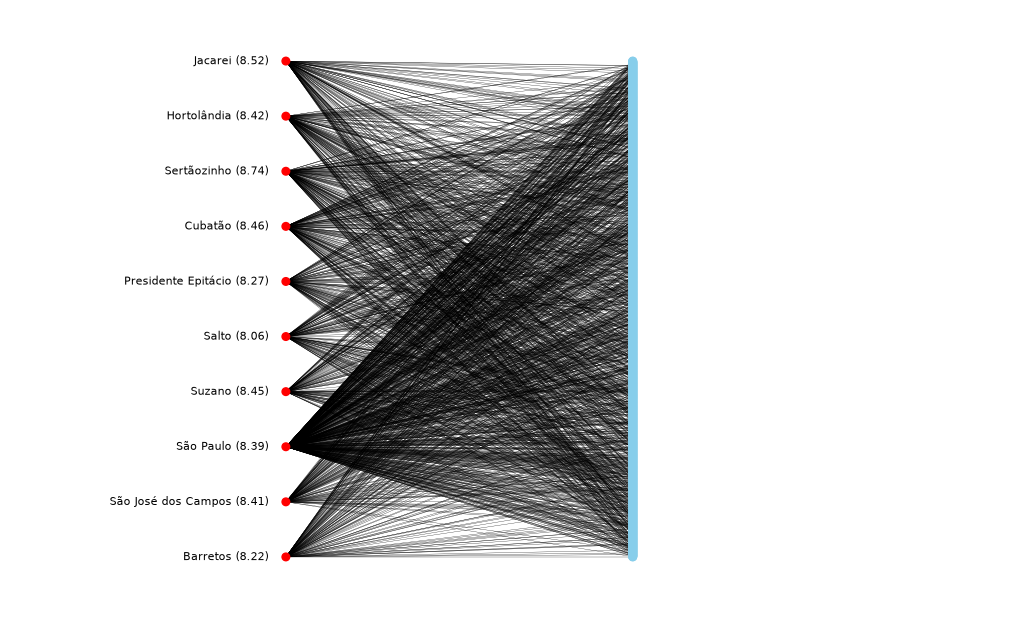

In [295]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.from_numpy_array(grafo)
nos_escolas = list(range(len(escolas)))

# Posições dos nós (escolas ficam na coluna da esquerda, x = -1)
pos = nx.bipartite_layout(G, nos_escolas, align='vertical')

# 1. Calcula (soma dos pesos / quantidade de arestas) para cada vértice da esquerda e monta o label
labels_esquerda = {}
for i in nos_escolas:
    soma_pesos = G.degree(i, weight='weight')
    qtd_arestas = G.degree(i)
    media_no = soma_pesos / qtd_arestas if qtd_arestas > 0 else 0
    labels_esquerda[i] = f'{escolas[i]} ({media_no:.2f})'

# 2. Cria uma posição deslocada um pouco para a esquerda (x - 0.05) para o texto não encostar no nó
pos_labels = {i: (x - 0.05, y) for i, (x, y) in pos.items() if i in nos_escolas}

cores = ['red'] * len(escolas) + ['skyblue'] * len(professores)

plt.figure(figsize=(10, 6))

# Desenha nós e arestas sem labels padrão
nx.draw(
    G, pos=pos, node_color=cores, node_size=30, width=0.2, with_labels=False
)

# 3. Desenha os labels da esquerda alinhados à direita
nx.draw_networkx_labels(
    G,
    pos=pos_labels,
    labels=labels_esquerda,
    font_size=8,
    horizontalalignment='right',
)

# Ajusta a margem esquerda (aumentei um pouco de -1.6 para -1.8 para caber o número sem cortar)
plt.xlim(-1.8, 1.1)
plt.tight_layout()
plt.show()

# **MODELOS**

## **Modelo Base**

O modelo base distribui os professores entre as escolas ignorando as disciplinas. O único objetivo é maximizar o menor grau entre os institutos. Pelo algoritmo guloso, do maior pro menor peso, cada professor vai pra escola que tem o menor grau no momento. Isso gera um alocação válida f com valor m(f) = o menor grau.
A alocação ótima ocorre quando m(f) = W*/|E| e, quando a desigualdade m(f) <= W*/|E| possui uma folga muito grande, devemos recorrer ao solver do excel.

Podemos notar que a discrepância entre o grau mínimo e máximo é desprezível, já que o desvio padrão é aproximadamente zero. Contudo, essa locação não é realista, pois ignora que cada unidade requer uma quantidade específica de professores por matéria. Essa limitação será corrigida nos próximos modelos.

In [296]:
#Melhor professor vai para a escola com menor grau
graus = {escola: 0 for escola in escolas}

for i in dados.sort_values('PESO', ascending=False).index:
    escola = min(graus, key=graus.get)
    graus[escola] += dados.loc[i, 'PESO']
    dados.loc[i, 'ALOCACAO'] = escola

m_f = min(graus.values())
limite = dados['PESO'].sum() // len(escolas)

#Separa os casos pelo resultado da disrepância entre W*/|E| e m(f)
print(f'm(f) = {m_f}  |  W*/|E| = {limite}  |  folga = {limite - m_f}')
print('Alocação ótima!' if m_f == limite else 'Pode existir alocação melhor (usar solver)')

g = dados.groupby('ALOCACAO')['PESO'].mean()
print(f'Mínimo: {g.min():.2f}  |  Máximo: {g.max():.2f}  |  Desvio padrão: {g.std():.2f}')


nova_distribuicao = copy.deepcopy(dados[[ 'SERVIDOR', ' EXERCICIO SIAPE', 'TITULACAO', 'PESO', 'DISCIPLINA', 'ALOCACAO']])

m(f) = 1423  |  W*/|E| = 1423  |  folga = 0
Alocação ótima!
Mínimo: 8.38  |  Máximo: 8.42  |  Desvio padrão: 0.02


In [297]:
nova_distribuicao

,SERVIDOR,EXERCICIO SIAPE,TITULACAO,PESO,DISCIPLINA,ALOCACAO
0,Abraao Pustrelo Damiao,Barretos,DOUTORADO,10,quimica,Sertãozinho
1,Adaiana Francisca Gomes da Silva,São José dos Campos,DOUTORADO,10,ingles,Cubatão
2,Adelino Zamprogno,São Paulo,ESPECIALIZACAO NIVEL SUPERIOR,6,sociologia,Salto
3,Ademir Sousa Henrique,São Paulo,ESPECIALIZACAO NIVEL SUPERIOR,6,geografia,Salto
4,Adilson de Melo Poggiato,Suzano,ESPECIALIZACAO NIVEL SUPERIOR,6,matematica,Suzano
...,...,...,...,...,...,...
1690,Wilson de Andrade Matos,São Paulo,MESTRADO,8,matematica,Suzano
1691,Wilson Mitsuo Uaquida,São Paulo,GRADUACAO (NIVEL SUPERIOR COMPLETO),3,biologia,Presidente Epitácio
1692,Wilson Sergio de Araujo Rocha,São José dos Campos,MESTRE+RSC-III (LEI 12772/12 ART 18),9,quimica,Barretos
1693,Wilson Yoshio Tanaka,Suzano,MESTRE+RSC-III (LEI 12772/12 ART 18),9,matematica,Jacarei


## **Modelo Final 1**

Nesse modelo utilizaremos o que foi construido acima, mas dessa vez levando em consideração as matérias de cada professor em consideração e a quantidade de professores de cada matéria necessários para cada escola.

Ele inicia um loop que passa por cada matéria, dentro do loop que passa por todas as matérias, ele possui outro loop o qual passa de professor em professor por ordem de titulação
da maior titulação para a menor. Nesse loop, ele escolhe a escola que possui a menor nota média naquele momento sendo a formula da nota média:

$$\sum_{i=1}^{n} x_i \cdot \frac{1}{n}$$

Sendo $x_i$ = pesos dos professores já adicionados e $n$ = número de professores necessários naquela matéria e escola.
Ao terminar de preencher os professores da matéria de certa escola, ele retira ela da variável **graus** temporariamente para alocar para outras escolas.


In [298]:
#professores_por_disciplina
#professores_por_disciplina.to_dict()

In [299]:
materias = dados['DISCIPLINA'].unique() #Criando lista com todas as materias
materias

<StringArray>
[        'quimica',          'ingles',      'sociologia',       'geografia',
      'matematica',       'portugues', 'educacao fisica',           'artes',
       'filosofia',          'fisica',        'historia',        'biologia']
Length: 12, dtype: str

In [300]:
#Melhor professor da materia vai para a escola com menor grau da materia

graus = {
    escola: {
        materia: [0, professores_por_disciplina[materia][escola]]
        for materia in materias
    }
    for escola in escolas
}
#graus é uma variavel com as informações: 
#escola(string com nome da escola): {materias(materias da variavel materias) = [soma dos pesos dos professores, quantidade necessaria da materia]}


graus_reserva = copy.deepcopy(graus) #copia para usar dentro do loop
peso_total = {escola: 0 for escola in escolas}

for materia in materias:
    graus = copy.deepcopy(graus_reserva)
    for i in dados[dados['DISCIPLINA'] == materia].sort_values('PESO', ascending=False).index:
        escola = min(graus, key=lambda e: graus[e][materia][0] / graus_reserva[e][materia][1]) #a funcao lambda verifica escola a escola.
        #print(escola, graus_reserva[escola][materia][1], graus[escola][materia][1])
        graus[escola][materia][0] += dados.loc[i, 'PESO']
        graus[escola][materia][1] -= 1 #Remove a quantidade de professores faltantes da matéria
        dados.loc[i, 'ALOCACAO'] = escola
        peso_total[escola] += dados.loc[i, 'PESO']

        if graus[escola][materia][1] == 0:
           del graus[escola] #Retira a escola do dicionario graus quando atinge a quantidade de professores necessarios na materia

m_f = min(peso_total.values())
limite = dados['PESO'].sum() // len(escolas)

#Separa os casos pelo resultado da disrepância entre W*/|E| e m(f)
print(f'm(f) = {m_f}  |  W*/|E| = {limite}  |  folga = {limite - m_f}')
print('Alocação ótima!' if m_f == limite else 'Pode existir alocação melhor (usar solver)')

g = dados.groupby('ALOCACAO')['PESO'].mean()
print(f'Mínimo: {g.min():.2f}  |  Máximo: {g.max():.2f}  |  Desvio padrão: {g.std():.2f}')

nova_distribuicao = copy.deepcopy(dados[[ 'SERVIDOR', ' EXERCICIO SIAPE', 'TITULACAO', 'PESO', 'DISCIPLINA', 'ALOCACAO']])

m(f) = 987  |  W*/|E| = 1423  |  folga = 436
Pode existir alocação melhor (usar solver)
Mínimo: 8.26  |  Máximo: 8.52  |  Desvio padrão: 0.08


In [301]:
dados.pivot_table(index='ALOCACAO', columns='DISCIPLINA', values='PESO', aggfunc='mean').round(2)

DISCIPLINA,artes,biologia,educacao fisica,filosofia,fisica,geografia,historia,ingles,matematica,portugues,quimica,sociologia
ALOCACAO,,,,,,,,,,,,
Barretos,8.83,8.00,8.62,8.00,8.73,8.46,8.43,8.89,8.60,8.50,8.43,8.43
Cubatão,8.67,8.00,8.31,8.00,8.73,8.75,8.25,8.92,8.56,8.37,8.27,8.12
Hortolândia,8.75,8.00,8.25,8.00,8.64,8.45,8.50,8.86,8.56,8.40,8.21,8.33
Jacarei,8.83,8.60,8.50,8.33,8.80,8.45,8.50,9.00,8.56,8.30,8.23,9.00
Presidente Epitácio,8.83,8.07,8.43,7.90,8.75,8.70,8.50,9.25,8.62,8.35,8.75,8.60
Salto,8.86,8.00,8.30,8.33,8.50,8.43,8.50,9.00,8.57,8.64,8.27,8.50
Sertãozinho,8.40,8.25,8.43,8.00,8.53,8.60,8.18,8.67,8.58,8.33,8.56,8.12
Suzano,8.86,8.00,8.75,8.60,9.00,8.67,8.14,8.89,8.62,8.35,8.56,8.60
São José dos Campos,8.62,8.09,8.62,7.92,8.75,8.55,8.45,9.00,8.58,8.60,8.62,8.33


In [302]:
g

ALOCACAO
Barretos               8.483871
Cubatão                8.394737
Hortolândia            8.427481
Jacarei                8.515873
Presidente Epitácio    8.466102
Salto                  8.491803
Sertãozinho            8.418919
Suzano                 8.508621
São José dos Campos    8.491525
São Paulo              8.264815
Name: PESO, dtype: float64

In [303]:
nova_distribuicao

,SERVIDOR,EXERCICIO SIAPE,TITULACAO,PESO,DISCIPLINA,ALOCACAO
0,Abraao Pustrelo Damiao,Barretos,DOUTORADO,10,quimica,Barretos
1,Adaiana Francisca Gomes da Silva,São José dos Campos,DOUTORADO,10,ingles,Barretos
2,Adelino Zamprogno,São Paulo,ESPECIALIZACAO NIVEL SUPERIOR,6,sociologia,São Paulo
3,Ademir Sousa Henrique,São Paulo,ESPECIALIZACAO NIVEL SUPERIOR,6,geografia,São Paulo
4,Adilson de Melo Poggiato,Suzano,ESPECIALIZACAO NIVEL SUPERIOR,6,matematica,São Paulo
...,...,...,...,...,...,...
1690,Wilson de Andrade Matos,São Paulo,MESTRADO,8,matematica,Hortolândia
1691,Wilson Mitsuo Uaquida,São Paulo,GRADUACAO (NIVEL SUPERIOR COMPLETO),3,biologia,Presidente Epitácio
1692,Wilson Sergio de Araujo Rocha,São José dos Campos,MESTRE+RSC-III (LEI 12772/12 ART 18),9,quimica,Suzano
1693,Wilson Yoshio Tanaka,Suzano,MESTRE+RSC-III (LEI 12772/12 ART 18),9,matematica,São Paulo


In [304]:
def criar_arestas_versao1(vertice,vertices:list, arestas:list = []):
    #A variavel vertices sao os vertice que o vertice guardado na variavel vertices se liga, arestas guarda quais arestas ja existem.

    for cada_vertice in vertices:
        arestas.append((vertice, cada_vertice))

    return arestas

In [305]:
for cada_escola, grupo in nova_distribuicao.groupby('ALOCACAO'):
    professores = grupo['SERVIDOR'].tolist()
    arestas_versao1 = criar_arestas_versao1(cada_escola, professores)
    arestas_versao1 = adicionar_peso(arestas_versao1, nova_distribuicao)


In [306]:
grafo = criar_grafo(vertices,arestas_versao1)

C:\Users\leohs\AppData\Local\Temp\ipykernel_25480\1430744828.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


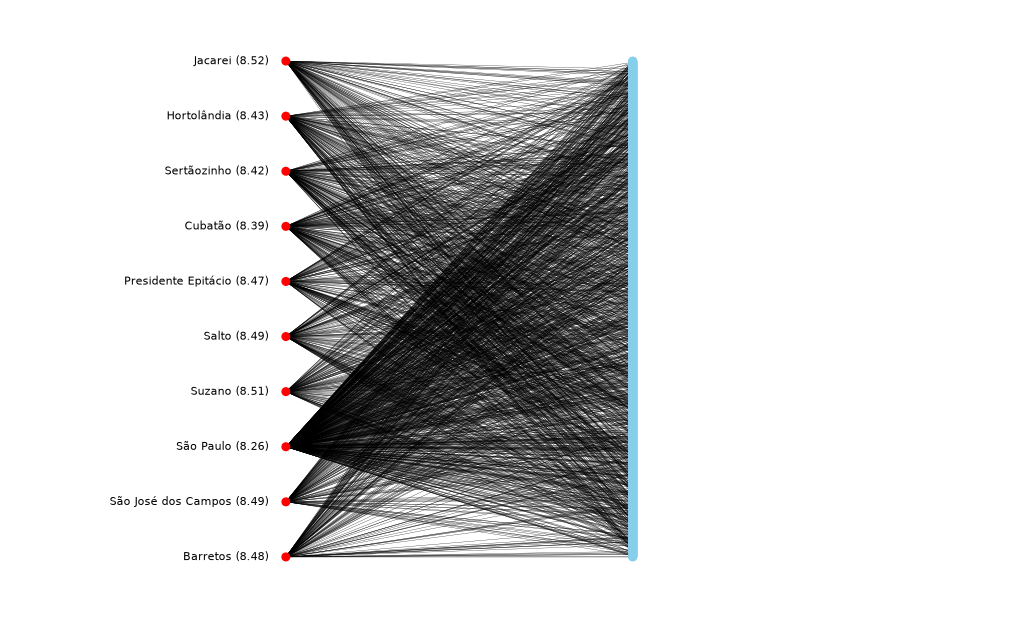

In [307]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.from_numpy_array(grafo)
nos_escolas = list(range(len(escolas)))

# Posições dos nós (escolas ficam na coluna da esquerda, x = -1)
pos = nx.bipartite_layout(G, nos_escolas, align='vertical')

# 1. Calcula (soma dos pesos / quantidade de arestas) para cada vértice da esquerda
labels_esquerda = {}
for i in nos_escolas:
    soma_pesos = G.degree(i, weight='weight')
    qtd_arestas = G.degree(i)
    media_no = soma_pesos / qtd_arestas if qtd_arestas > 0 else 0
    labels_esquerda[i] = f'{escolas[i]} ({media_no:.2f})'

# 2. Cria uma posição deslocada um pouco para a esquerda
pos_labels = {i: (x - 0.05, y) for i, (x, y) in pos.items() if i in nos_escolas}

# --- CORREÇÃO DAS CORES ---
# Garante que 'cores' tenha exatamente o mesmo número de nós de G (1705)
qtd_total_nos = G.number_of_nodes()
cores = ['red' if i < len(escolas) else 'skyblue' for i in range(qtd_total_nos)]
# --------------------------

plt.figure(figsize=(10, 6))

nx.draw(
    G, pos=pos, node_color=cores, node_size=30, width=0.2, with_labels=False
)

nx.draw_networkx_labels(
    G,
    pos=pos_labels,
    labels=labels_esquerda,
    font_size=8,
    horizontalalignment='right',
)

plt.xlim(-1.8, 1.1)
plt.tight_layout()
plt.show()

## **Modelo Final 2**

O modelo final 2 é similar ao modelo base, mas distribui os professores respeitando a quantidade de vagas de cada escola em cada matéria. Como as escolas têm tamanhos muito diferentes, a soma dos pesos não é comparável entre elas (uma escola com mais professores tem soma maior mesmo com professores de menor titulação). Por isso, o objetivo passa a ser maximizar o **grau médio** da escola mais fraca.

**Formulação.** Seja $E$ o conjunto de escolas, $K$ o de matérias, $P_k$ o conjunto de professores da matéria $k$, $w_p$ o peso do professor $p$ e $q_{e,k}$ o número de vagas da escola $e$ na matéria $k$ (com $\sum_e q_{e,k} = |P_k|$). Defina o tamanho da escola $n_e = \sum_{k \in K} q_{e,k}$ e $N = \sum_{e \in E} n_e$. Com $x_{p,e} \in \{0,1\}$ indicando que $p$ é alocado a $e$:

$$\max \; \min_{e \in E} \bar G_e, \qquad \bar G_e = \frac{G_e}{n_e}, \qquad G_e = \sum_{k \in K} \sum_{p \in P_k} w_p\, x_{p,e}$$

$$\text{sujeito a} \quad \sum_{e} x_{p,e} = 1 \;\; \forall p, \qquad \sum_{p \in P_k} x_{p,e} = q_{e,k} \;\; \forall e, k$$

Como $\sum_e n_e \bar G_e = \sum_e G_e = W$ (soma de todos os pesos), o mínimo das médias não supera a média ponderada delas:

$$m(f) = \min_{e \in E} \bar G_e \le \frac{W}{N}$$

Esse é o limite superior do modelo (no modelo base era $W/|E|$, pois todas as escolas tinham o mesmo tamanho).

**Algoritmo (heurística em duas fases).**
1. *Guloso:* do maior para o menor peso, cada professor vai para a escola de menor grau médio $G_e/n_e$ entre as que ainda têm vaga na matéria dele.
2. *Trocas:* a escola mais fraca (menor média) $w$ troca um professor com uma escola mais forte $f$, da mesma matéria (as vagas não mudam), desde que receba um peso maior, com ganho $d > 0$, e a escola forte continue acima dela:

$$\frac{G_f - d}{n_f} > \frac{G_w}{n_w} \iff d\, n_w < G_f\, n_w - G_w\, n_f$$

Repete até não haver troca possível.

**Hipótese:** as vagas $q_{e,k}$ foram tomadas de `professores_por_disciplina` (a distribuição atual), e são mantidas de propósito. Como elas fixam o tamanho $n_e$ de cada escola, o objetivo é a média e não a soma. Se as necessidades reais forem outras, basta substituir o dicionário `vagas`.

In [308]:
#Vagas (necessidade) de cada escola por disciplina: vagas[escola][disciplina]
vagas = {e: dict(linha) for e, linha in professores_por_disciplina.iterrows()}
vagas_iniciais = {e: dict(v) for e, v in vagas.items()}
n = {e: sum(vagas_iniciais[e].values()) for e in escolas}

#Fase 1: guloso - do maior peso para o menor, o professor vai para a escola
#de menor grau TOTAL entre as que ainda tem vaga na disciplina dele
graus2 = {escola: 0 for escola in escolas}
membros = {e: {k: [] for k in disciplinas} for e in escolas}   # (peso, id) por escola e disciplina

for i in dados.sort_values('PESO', ascending=False, kind='stable').index:
    k, peso = dados.loc[i, 'DISCIPLINA'], int(dados.loc[i, 'PESO'])
    candidatas = [e for e in escolas if vagas[e][k] > 0]
    escola = min(candidatas, key=lambda e: graus2[e] / n[e])
    vagas[escola][k] -= 1
    graus2[escola] += peso
    membros[escola][k].append((peso, i))

#Fase 2: trocas entre professores da MESMA disciplina (mantem as vagas).
#A escola mais fraca troca com uma escola mais forte, recebendo um professor
#de peso maior; so troca se a escola mais forte continuar acima da mais fraca.
while True:
    fraca = min(escolas, key=lambda e: graus2[e] / n[e])
    melhor = None                                   # (d, forte, k, a, b)
    for forte in escolas:
        folga = graus2[forte]*n[fraca] - graus2[fraca]*n[forte]
        if forte == fraca or folga <= 0:
            continue
        for k in disciplinas:
            for a in membros[fraca][k]:
                for b in membros[forte][k]:
                    d = b[0] - a[0]
                    if 0 < d and d*n[fraca] < folga and (melhor is None or d > melhor[0]):
                        melhor = (d, forte, k, a, b)
    if melhor is None:
        break
    d, forte, k, a, b = melhor
    membros[fraca][k].remove(a);  membros[forte][k].remove(b)
    membros[fraca][k].append(b);  membros[forte][k].append(a)
    graus2[fraca] += d;  graus2[forte] -= d

#Registrando o resultado
for e in escolas:
    for k in disciplinas:
        for _, i in membros[e][k]:
            dados.loc[i, 'ALOCACAO2'] = e

#Verificacoes e resultados
m_f2 = min(graus2[e] / n[e] for e in escolas)
limite = dados['PESO'].sum() / len(dados)
alocadas = pd.crosstab(dados['ALOCACAO2'], dados['DISCIPLINA'])
assert (alocadas.reindex_like(professores_por_disciplina).fillna(0).values
        == professores_por_disciplina.values).all(), 'vagas por disciplina nao respeitadas'

print(f'm(f) = {m_f2:.2f}  |  W/N = {limite:.2f}  |  folga = {limite - m_f2:.2f}')
g2 = dados.groupby('ALOCACAO2')['PESO'].mean()
print(f'grau medio - minimo: {g2.min():.2f}  maximo: {g2.max():.2f}  desvio padrao: {g2.std():.2f}')

#Grau medio por escola e disciplina (mostra que a disciplina pode ficar desbalanceada)
dados.pivot_table(index='ALOCACAO2', columns='DISCIPLINA', values='PESO', aggfunc='mean').round(2)


m(f) = 8.40  |  W/N = 8.40  |  folga = 0.00
grau medio - minimo: 8.40  maximo: 8.41  desvio padrao: 0.00


DISCIPLINA,artes,biologia,educacao fisica,filosofia,fisica,geografia,historia,ingles,matematica,portugues,quimica,sociologia
ALOCACAO2,,,,,,,,,,,,
Barretos,8.67,9.11,9.62,5.82,8.82,9.31,9.14,9.56,7.47,8.29,7.43,9.57
Cubatão,8.78,6.13,8.50,6.45,9.18,9.75,10.00,7.58,8.56,9.26,8.73,8.12
Hortolândia,10.00,8.62,7.58,8.22,8.29,7.45,8.00,8.57,8.81,7.33,9.50,10.00
Jacarei,9.83,10.00,9.12,9.83,7.00,7.75,8.62,8.67,8.94,7.96,7.69,10.00
Presidente Epitácio,7.67,5.79,8.14,9.00,10.00,8.60,7.10,10.00,9.62,9.00,9.50,8.00
Salto,9.57,9.67,9.70,7.00,6.67,8.07,8.38,8.00,7.76,9.55,8.64,9.25
Sertãozinho,7.80,9.88,9.21,9.50,8.13,9.20,9.18,8.33,7.68,7.14,9.56,7.38
Suzano,9.43,6.92,10.00,7.60,10.00,9.50,8.43,7.78,8.25,8.18,8.33,8.60
São José dos Campos,6.75,8.82,7.88,7.62,7.83,8.45,8.55,10.00,9.33,8.80,9.38,7.00


In [309]:
print(professores_por_disciplina.sum(axis=1))
print(dados.groupby('ALOCACAO2')['PESO'].agg(['count', 'mean', 'sum']))

 EXERCICIO SIAPE
Barretos               124
Cubatão                152
Hortolândia            131
Jacarei                126
Presidente Epitácio    118
Salto                  122
Sertãozinho            148
Suzano                 116
São José dos Campos    118
São Paulo              540
dtype: int64
                     count      mean   sum
ALOCACAO2                                 
Barretos               124  8.403226  1042
Cubatão                152  8.401316  1277
Hortolândia            131  8.396947  1100
Jacarei                126  8.404762  1059
Presidente Epitácio    118  8.398305   991
Salto                  122  8.401639  1025
Sertãozinho            148  8.398649  1243
Suzano                 116  8.405172   975
São José dos Campos    118  8.398305   991
São Paulo              540  8.398148  4535


In [310]:
dados

,SERVIDOR,EXERCICIO SIAPE,LOTACAO SIAPE,CARGO EMPREGO,DATA POSSE NO CARGO,FUNCAO DISPLAY,JORNADA TRABALHO,NOME DO SETOR DE EXERCÍCIO POR EXTENSO,SITUACAO,TITULACAO,PESO,ID,DISCIPLINA,ALOCACAO,ALOCACAO2
0,Abraao Pustrelo Damiao,Barretos,Barretos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,22/09/2014,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DA AREA DE ALIMENTOS,ATIVO PERMANENTE - 01,DOUTORADO,10,0,quimica,Barretos,Barretos
1,Adaiana Francisca Gomes da Silva,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,09/09/2014,NaN,DEDICACAO EXCLUSIVA,COORD DO CURSO DE ENGENHARIA MECANICA,ATIVO PERMANENTE - 01,DOUTORADO,10,1,ingles,Barretos,São José dos Campos
2,Adelino Zamprogno,São Paulo,São Paulo,ASSISTENTE EM ADMINISTRACAO (PCIFE) - 701200,09/08/2021,FG1,40 HORAS SEMANAIS,COORDENADORIA DE LICITACOES,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,2,sociologia,São Paulo,São Paulo
3,Ademir Sousa Henrique,São Paulo,São Paulo,TECNICO EM ASSUNTOS EDUCACIONAIS (PCIFE) - 701079,17/08/2020,NaN,40 HORAS SEMANAIS,COORDENADORIA DE BIBLIOTECA,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,3,geografia,São Paulo,São Paulo
4,Adilson de Melo Poggiato,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,40 HORAS SEMANAIS,COORD DE CURSO TECNICO EM AUT INDUSTRIAL,ATIVO PERMANENTE - 01,ESPECIALIZACAO NIVEL SUPERIOR,6,4,matematica,São Paulo,São Paulo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690,Wilson de Andrade Matos,São Paulo,São Paulo,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,REPRES. DA SUBAREA DE FISICA,ATIVO PERMANENTE - 01,MESTRADO,8,1690,matematica,Hortolândia,Hortolândia
1691,Wilson Mitsuo Uaquida,São Paulo,São Paulo,TECNICO DE LABORATORIO AREA (PCIFE) - 701244,27/03/2013,NaN,40 HORAS SEMANAIS,SUB AREA DE ELETRICA 4,ATIVO PERMANENTE - 01,GRADUACAO (NIVEL SUPERIOR COMPLETO),3,1691,biologia,Presidente Epitácio,Cubatão
1692,Wilson Sergio de Araujo Rocha,São José dos Campos,São José dos Campos,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,01/03/2013,NaN,DEDICACAO EXCLUSIVA,COORD CURSO DE LICENCIATURA EM QUIMICA,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18),9,1692,quimica,Suzano,Sertãozinho
1693,Wilson Yoshio Tanaka,Suzano,Suzano,PROFESSOR ENS BASICO TECN TECNOLOGICO (CMEBT) ...,06/06/2016,NaN,DEDICACAO EXCLUSIVA,COORDENADORIA DE CURSO TEC EM ADM E COM,ATIVO PERMANENTE - 01,MESTRE+RSC-III (LEI 12772/12 ART 18),9,1693,matematica,São Paulo,São Paulo


In [311]:
def criar_arestas_versao2(vertice,vertices:list, arestas:list = []):
    #A variavel vertices sao os vertice que o vertice guardado na variavel vertices se liga, arestas guarda quais arestas ja existem.

    for cada_vertice in vertices:
        arestas.append((vertice, cada_vertice))

    return arestas

In [312]:
for cada_escola, grupo in dados.groupby('ALOCACAO2'):
    professores = grupo['SERVIDOR'].tolist()
    arestas_versao2 = criar_arestas_versao2(cada_escola, professores)
    arestas_versao2 = adicionar_peso(arestas_versao2,dados),



In [314]:
print(type(arestas_versao2), len(arestas_versao2))
print(type(arestas_versao2[0]), len(arestas_versao2[0]))
print(arestas_versao2[0][:5])  # mostra os primeiros elementos do item 0

<class 'tuple'> 1
<class 'list'> 1695
[('Barretos', 'Abraao Pustrelo Damiao', 10), ('Barretos', 'Adriane Figueiredo Murari', 2), ('Barretos', 'Ailson Vasconcelos da Cunha', 9), ('Barretos', 'Alessandra Vetorelli Pereira', 8), ('Barretos', 'Alessandro Rossi Lopes', 6)]


In [317]:
grafo = criar_grafo(vertices,arestas_versao2[0])

C:\Users\leohs\AppData\Local\Temp\ipykernel_25480\1430744828.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


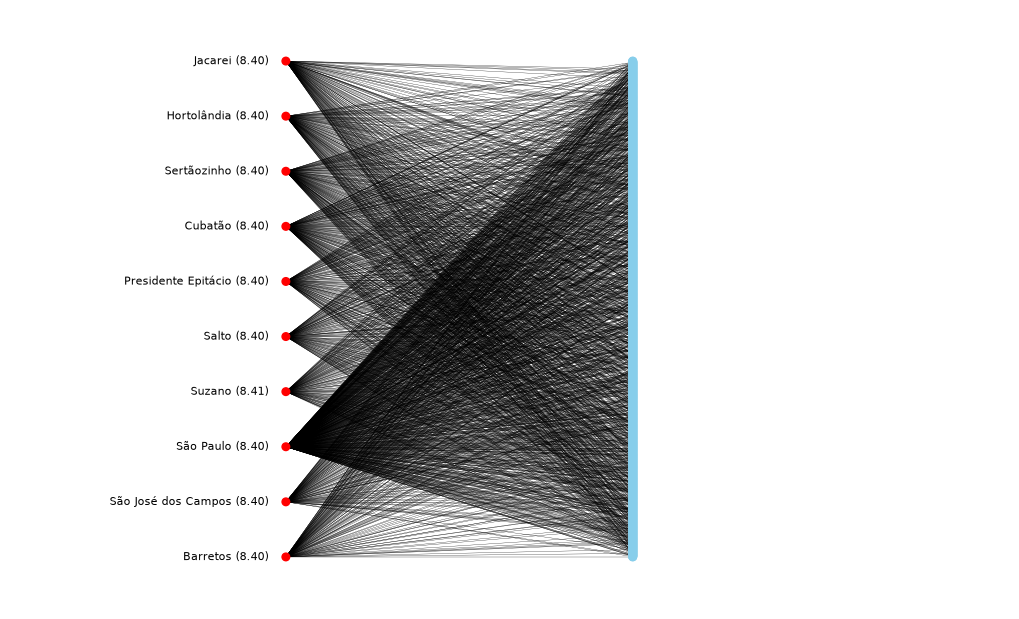

In [318]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.from_numpy_array(grafo)
nos_escolas = list(range(len(escolas)))

# Posições dos nós (escolas ficam na coluna da esquerda, x = -1)
pos = nx.bipartite_layout(G, nos_escolas, align='vertical')

# 1. Calcula (soma dos pesos / quantidade de arestas) para cada vértice da esquerda
labels_esquerda = {}
for i in nos_escolas:
    soma_pesos = G.degree(i, weight='weight')
    qtd_arestas = G.degree(i)
    media_no = soma_pesos / qtd_arestas if qtd_arestas > 0 else 0
    labels_esquerda[i] = f'{escolas[i]} ({media_no:.2f})'

# 2. Cria uma posição deslocada um pouco para a esquerda
pos_labels = {i: (x - 0.05, y) for i, (x, y) in pos.items() if i in nos_escolas}

# --- CORREÇÃO DAS CORES ---
# Garante que 'cores' tenha exatamente o mesmo número de nós de G (1705)
qtd_total_nos = G.number_of_nodes()
cores = ['red' if i < len(escolas) else 'skyblue' for i in range(qtd_total_nos)]
# --------------------------

plt.figure(figsize=(10, 6))

nx.draw(
    G, pos=pos, node_color=cores, node_size=30, width=0.2, with_labels=False
)

nx.draw_networkx_labels(
    G,
    pos=pos_labels,
    labels=labels_esquerda,
    font_size=8,
    horizontalalignment='right',
)

plt.xlim(-1.8, 1.1)
plt.tight_layout()
plt.show()